# Ground states: H₄, LiH, H₂O, N₂

Ground-state energies with the two DMRG drivers — one-site **ALS** on a fixed manifold, and
two-site **MALS**, which adapts the ranks as it sweeps — across four systems spanning three orders
of magnitude in Hilbert-space size.

In [1]:
# Use the notebook environment (see notebooks/Project.toml) regardless of which kernel started us.
using Pkg
Pkg.activate(@__DIR__)

  Activating 

project at `~/Dropbox/Workplace/RustPackages/qntt/notebooks`


In [2]:
using QNTT, LinearAlgebra, Printf, Plots
gr()
QNTT.init()
@printf("qntt %s, %d threads\n", QNTT.version(), QNTT.nthreads())

# Where the integral fixtures live, and a loader for the pyscf-exported `meta/h1/h2` format
# (used by the LiH and N2 fixtures that are not FCIDUMP files).
const ROOT = normpath(joinpath(@__DIR__, ".."))
fixture(parts...) = joinpath(ROOT, "testdata", parts...)

"""
Load a fixture directory: a keyed `meta.txt` plus the FCIDUMP its `dump_file` key names.

`e_ref` is *whatever reference the fixture was generated against*, and the meta says which by the
key it uses — `e_fci` where the determinant count allowed one, `e_ccsd_t` otherwise. It is never a
generic slot whose meaning varies per fixture (two fixtures used to record `e_ref == e_hf`, from a
skipped FCI silently falling back to the SCF energy).

These directories used to ship `h1.dat`/`h2.dat`: a dense positional dump with no write threshold,
which carried entries down to ~1e-22 where an FCIDUMP is written at 1e-15 — the same molecule with
materially different content (66% of `h2.dat` and 17.5% of the assembled operator at N₂/cc-pVDZ).
One format, so the question does not arise.
"""
function load_fixture(dir)
    meta = Dict{String,String}()
    for line in eachline(joinpath(dir, "meta.txt"))
        line = strip(line)
        (isempty(line) || startswith(line, "#")) && continue
        parts = split(line, limit = 2)
        length(parts) == 2 && (meta[parts[1]] = strip(parts[2]))
    end
    getf(k) = parse(Float64, meta[k])
    d      = parse(Int, meta["norb"])
    nelec  = parse(Int, meta["nelec"])
    ms2    = parse(Int, get(meta, "ms2", "0"))
    e_nuc  = getf("e_nuc")
    e_hf   = haskey(meta, "e_hf") ? getf("e_hf") : NaN
    refkey = findfirst(k -> haskey(meta, k), ["e_fci", "e_ccsd_t", "e_ccsd"])
    e_ref  = refkey === nothing ? NaN : getf(["e_fci", "e_ccsd_t", "e_ccsd"][refkey])

    ints = QNTT.read_fcidump(joinpath(dir, meta["dump_file"]))
    t, v = QNTT.onebody(ints), QNTT.twobody(ints)
    @assert size(t) == (d, d) "meta norb=$d disagrees with $(meta["dump_file"])"
    return (; t, v, d, nelec, ms2, e_nuc, e_hf, e_ref)
end

# --- the state cache ---------------------------------------------------------------------------
# The ground-state pipeline is deterministic and expensive (~2 minutes for water 6-31G at M = 64),
# while every downstream experiment repeats it verbatim. So: build once, save, and reuse. Cold on the first execution, warm in milliseconds
# thereafter.
#
# The cache is a local file, NOT an archival format: it records the build that wrote it and refuses
# anything else, and there is no migration path. If `load` ever complains, delete the file and let
# the cold path run again.
#
# It keys on the physical setup only (fixture, 2S, M and a tag). CHANGING A SOLVER KNOB DOES NOT
# INVALIDATE IT — delete `notebooks/cache/` by hand after editing the schedule below, or you will
# be reading a state built with the old one. The space is re-checked on load, so a change that
# alters the space is caught; one that only alters the path to the state is not.
const CACHE_DIR = joinpath(@__DIR__, "cache")
cache_file(tag) = joinpath(CACHE_DIR, tag * ".tt")

"""
    cached(T, L, tag, space, build) -> (x, :warm|:cold, seconds)

Return the cached state `tag`, or build it with `build()` and save it. The loaded state's space
must equal `space`, so a cache left over from a different physical setup is an error rather than a
silent wrong answer.
"""
function cached(::Type{T}, ::Type{L}, tag, space, build) where {T,L}
    path = cache_file(tag)
    if isfile(path)
        t = @elapsed x = QNTT.load(T, L, path)
        QNTT.space(x) == space ||
            error("cache $path holds $(QNTT.space(x)), but this run wants $space; delete it")
        return (x, :warm, t)
    end
    t = @elapsed x = build()
    mkpath(CACHE_DIR)
    QNTT.save(x, path)
    return (x, :cold, t)
end

report_cache(tag, how, t) = how === :warm ?
    @printf("cache HIT  %s — loaded in %.3f s (the pipeline below was skipped)\n", tag, t) :
    @printf("cache MISS %s — built in %.1f s and saved for next time\n", tag, t)

qntt 0.1.0, 16 threads


report_cache (generic function with 1 method)

## H₄ — the whole Hilbert space

Four orbitals, four electrons: the `(Nup, Ndn) = (2, 2)` sector holds `C(4,2)² = 36` determinants.
At full rank the tensor train is *exact*, so DMRG here returns the FCI energy. Notebook 03 returns
to this system.

In [3]:
h4 = QNTT.read_fcidump(fixture("h4.FCIDUMP"))
space4 = QNTT.QnSpace(h4)
H4 = QNTT.Hamiltonian(space4, h4)

@printf("%s, E_core = %.10f\n", string(space4), QNTT.e0(h4))
@printf("maximal bond dimensions per bond: %s\n",
        string([sum(g) for g in QNTT.maxranks(space4)]))

QnSpace(d=4, Nup=2, Ndn=2), E_core = 2.2931012473
maximal bond dimensions per bond: [1, 4, 16, 4, 1]


**ALS** optimizes on a *fixed* manifold — the rank grid of the starting state, which it never
leaves. Its knob is the **per-sector** rank: below full rank it returns the best state of that rank
(variational, above FCI); on the full manifold, FCI.

In [4]:
# ALS on manifolds of increasing per-sector rank. `total M` is the bond dimension summed over
# symmetry sectors — the number MALS caps below, and NOT the same number as the per-sector rank.
@printf("%-20s %8s %18s\n", "ALS per-sector rank", "total M", "λ")
for r in (1, 2, 4)
    x0 = QNTT.tt_randn(space4, QNTT.uniform_ranks(space4, r); seed = 7)
    λ, x = QNTT.als(H4, x0; eps = 1e-12, max_iter = 200)
    @printf("%-20d %8d %18.12f\n", r, QNTT.max_bond_rank(x), λ)
end

ALS per-sector rank   total M                  λ
1                           9    -4.430018351196


2                          14    -4.456884833443
4                          16    -4.459488695955


**MALS** grows the ranks itself as it sweeps. Its knob is the **total** bond dimension `M` summed
over all sectors — the conventional DMRG *M*, a different number from ALS's per-sector rank. Sweep
`M` up to the full manifold (here `M = 16`) and the energy falls monotonically to FCI.

In [5]:
Ms4 = [1, 2, 4, 8, 12, 16]
x0 = QNTT.tt_randn(space4, QNTT.uniform_ranks(space4, 1); seed = 7)
rows4 = map(Ms4) do M
    λ, x, _ = QNTT.mals(H4, x0; bond_dims = [M], eps = 1e-12, max_iter = 100)
    (; M, λ, bond = QNTT.max_bond_rank(x))
end

λ_exact = minimum(row.λ for row in rows4)
@printf("%-8s %18s %8s\n", "MALS M", "λ", "bond")
for row in rows4
    @printf("%-8d %18.12f %8d\n", row.M, row.λ, row.bond)
end
@printf("\nfull-rank (= FCI) electronic energy: %.12f Ha\n", λ_exact)
@printf("total energy: %.12f Ha\n", λ_exact + QNTT.e0(h4))

MALS M                    λ     bond
1           -4.391647184318        1


2           -4.426162030316        2
4           -4.454027139053        4
8           -4.459316342427        8
12          -4.459397138530       12
16          -4.459488695955       16

full-rank (= FCI) electronic energy: -4.459488695955 Ha
total energy: -2.166387448635 Ha


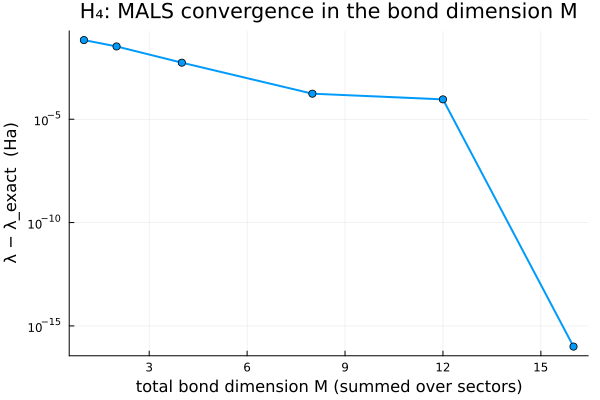

In [6]:
err = [max(row.λ - λ_exact, 1e-16) for row in rows4]
plot(Ms4, err;
     yscale = :log10, marker = :circle, lw = 2, legend = false,
     xlabel = "total bond dimension M (summed over sectors)",
     ylabel = "λ − λ_exact  (Ha)",
     title = "H₄: MALS convergence in the bond dimension M")

Both reach the exact energy once the manifold is large enough. Keep the two "rank" axes apart: ALS
reaches the full manifold at per-sector rank 4 (total `M = 16`), MALS at `M = 16`, and below full
rank ALS optimizes on the grid you hand it while MALS redistributes rank between sectors.

## LiH — a reference FCI energy to hit

Six orbitals, four electrons, STO-3G. pyscf's exact FCI energy ships with the fixture, so the
answer can be checked rather than merely watched to converge.

In [7]:
lih = load_fixture(fixture("lih_sto3g"))
space_li = QNTT.QnSpace(lih.d, lih.nelec, lih.ms2, Val(:from_sz))
H_li = QNTT.Hamiltonian(space_li, lih.t, lih.v)

@printf("%s\n", string(space_li))
@printf("E_nuc = %.10f   E_HF = %.10f   E_FCI = %.10f  (exact, pyscf)\n",
        lih.e_nuc, lih.e_hf, lih.e_ref)

QnSpace(d=6, Nup=2, Ndn=2)
E_nuc = 0.9953176381   E_HF = -7.8620238601   E_FCI = -7.8824019323  (exact, pyscf)


In [8]:
x0 = QNTT.tt_randn(space_li, QNTT.uniform_ranks(space_li, 8); seed = 11)
λ, x_li, _ = QNTT.mals(H_li, x0; bond_dims = [0], eps = 1e-12, max_iter = 60)

E_total = λ + lih.e_nuc
@printf("MALS electronic λ   = %.12f Ha\n", λ)
@printf("total E = λ + E_nuc = %.12f Ha\n", E_total)
@printf("exact E_FCI         = %.12f Ha\n", lih.e_ref)
@printf("difference          = %.2e Ha\n", E_total - lih.e_ref)
@printf("correlation energy recovered: %.10f Ha\n", lih.e_hf - E_total)

MALS electronic λ   = -8.877719570384 Ha
total E = λ + E_nuc = -7.882401932290 Ha


exact E_FCI         = -7.882401932290 Ha
difference          = 1.78e-15 Ha


correlation energy recovered: 0.0203780722 Ha


## H₂O — a real DMRG-scale problem

24 orbitals, 10 electrons; the answer now genuinely depends on the bond dimension. Two changes
matter at this size:

1. **Start from the Hartree–Fock determinant**, not from noise — a rank-1 train of the right order
   of magnitude that MALS grows rank around.
2. **Ramp the rank schedule.** `bond_dims` is read one entry per outer iteration, so `[8, 16, 32,
   …]` does the cheap sweeps first.

In [9]:
h2o = QNTT.read_fcidump(fixture("h2o.FCIDUMP"))
space_w = QNTT.QnSpace(h2o)
t0 = time()
H_w = QNTT.Hamiltonian(space_w, h2o)
@printf("%s\n", string(space_w))
@printf("operator built in %.1f s; largest automaton bond dimension %d\n",
        time() - t0, maximum(QNTT.automaton_bond_dims(H_w)))

# The Hartree–Fock determinant: fill the lowest `Nup` orbitals of each spin.
hf_w = QNTT.tt_state([k < space_w.a for k in 0:space_w.d-1],
                     [k < space_w.b for k in 0:space_w.d-1])
E_hf_w = QNTT.rayleigh_quotient(H_w, hf_w) + QNTT.e0(h2o)
@printf("Hartree–Fock determinant: E = %.8f Ha\n", E_hf_w)

QnSpace(d=24, Nup=5, Ndn=5)
operator built in 3.4 s; largest automaton bond dimension 31046


Hartree–Fock determinant: E = -76.02676567 Ha


In [10]:
ramp(r) = [min(r, 2^k) for k in 3:12]      # 8, 16, 32, … capped at r

rows_w = map([8, 16, 32, 64]) do r
    t = @elapsed λ, x, _ = QNTT.mals(H_w, hf_w; bond_dims = ramp(r), eps = 1e-9, max_iter = 14)
    E = λ + QNTT.e0(h2o)
    @printf("  ramp→%-4d  E = %.8f Ha   E_corr = %.6f   %5.1f s   bond = %d\n",
            r, E, E - E_hf_w, t, QNTT.max_bond_rank(x))
    (; r, E, bond = QNTT.max_bond_rank(x), t)
end

  ramp→8     E = -76.07724974 Ha   E_corr = -0.050484     1.8 s   bond = 8
  ramp→16    E = -76.07757136 Ha   E_corr = -0.050806     2.4 s   bond = 16


  ramp→32    E = -76.07761935 Ha   E_corr = -0.050854     2.5 s   bond = 32
  ramp→64    E = -76.07762017 Ha   E_corr = -0.050855     3.9 s   bond = 64


4-element Vector{@NamedTuple{r::Int64, E::Float64, bond::Int64, t::Float64}}:
 (r = 8, E = -76.07724974187332, bond = 8, t = 1.760872502)
 (r = 16, E = -76.07757135757038, bond = 16, t = 2.413017843)
 (r = 32, E = -76.07761935349617, bond = 32, t = 2.472907412)
 (r = 64, E = -76.07762017387843, bond = 64, t = 3.943268582)

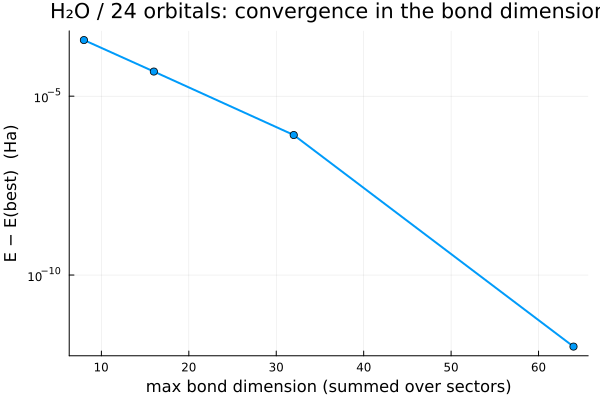

In [11]:
E_best_w = minimum(row.E for row in rows_w)
plot([row.bond for row in rows_w], max.([row.E - E_best_w for row in rows_w], 1e-12);
     yscale = :log10, marker = :circle, lw = 2, legend = false,
     xlabel = "max bond dimension (summed over sectors)",
     ylabel = "E − E(best)  (Ha)",
     title = "H₂O / 24 orbitals: convergence in the bond dimension")

The energy stops moving around bond dimension 32–64. Here the manifold never becomes exact, only
*sufficient*, so the curve flattens above the noise floor instead of collapsing as it did on H₄.

Diagnostic: if `max_bond_rank(x)` comes back sitting exactly on the cap, the cap — not the
truncation tolerance — decided the answer.

## N₂ / cc-pVDZ — with a reference to hit, and a trap to fall into

28 orbitals, 14 electrons, canonical RHF orbitals. The reference is **CCSD(T)**, not FCI, so
"correlation energy recovered" is measured against it. `bond_dims` caps the **total** bond
dimension summed over sectors — the conventional DMRG *M*. `M = 64` is small here; production runs
use 10³–10⁴.

In [12]:
n2 = load_fixture(fixture("n2_ccpvdz"))
space_n = QNTT.QnSpace(n2.d, n2.nelec, n2.ms2, Val(:from_sz))

t0 = time()
H_n = QNTT.Hamiltonian(space_n, n2.t, n2.v)
@printf("%s\n", string(space_n))
@printf("operator built in %.1f s; largest automaton bond dimension %d\n",
        time() - t0, maximum(QNTT.automaton_bond_dims(H_n)))

hf_n = QNTT.tt_state([k < space_n.a for k in 0:space_n.d-1],
                     [k < space_n.b for k in 0:space_n.d-1])
E_hf_tt = QNTT.rayleigh_quotient(H_n, hf_n) + n2.e_nuc

@printf("\nHartree–Fock determinant : %.8f Ha\n", E_hf_tt)
@printf("fixture reference E_HF   : %.8f Ha   (difference %.1e)\n",
        n2.e_hf, E_hf_tt - n2.e_hf)
@printf("CCSD(T) reference        : %.8f Ha\n", n2.e_ref)
@printf("correlation energy to recover: %.6f Ha\n", n2.e_ref - n2.e_hf)
@printf("chemical accuracy (1 kcal/mol) = %.6f Ha\n", 1 / 627.509474)

QnSpace(d=28, Nup=7, Ndn=7)
operator built in 9.6 s; largest automaton bond dimension 83936



Hartree–Fock determinant : -108.94937788 Ha
fixture reference E_HF   : -108.94937788 Ha   (difference -5.7e-14)


CCSD(T) reference        : -109.28030507 Ha
correlation energy to recover: -0.330927 Ha
chemical accuracy (1 kcal/mol) = 0.001594 Ha


The Hartree–Fock determinant, evaluated as a rank-1 tensor train, reproduces the fixture's
reference HF energy to the last digit — a good check that the integrals, the orbital ordering and
the operator all line up before anything harder is attempted.

Now sweep the bond dimension, starting from that determinant.

In [13]:
const KCAL = 627.509474                        # Hartree -> kcal/mol
recovered(E) = 100 * (n2.e_hf - E) / (n2.e_hf - n2.e_ref)
kcal(E) = KCAL * (E - n2.e_ref)                # distance from the reference, kcal/mol

rows_n = map([16, 32, 64, 128]) do r
    t = @elapsed λ, x = QNTT.mals(H_n, hf_n; bond_dims = ramp(r), eps = 1e-9, max_iter = 16)
    E = λ + n2.e_nuc
    @printf("  M→%-4d  E = %.8f   recovered %5.1f%%   %+7.1f kcal/mol   %5.1f s   M = %d\n",
            r, E, recovered(E), kcal(E), t, QNTT.max_bond_rank(x))
    (; r, E, bond = QNTT.max_bond_rank(x), t)
end

  M→16    E = -109.06379005   recovered  34.6%    +135.9 kcal/mol     4.5 s   M = 16
  M→32    E = -109.06464806   recovered  34.8%    +135.3 kcal/mol    11.5 s   M = 32


  M→64    E = -109.06479246   recovered  34.9%    +135.2 kcal/mol    13.6 s   M = 64
  M→128   E = -109.06479319   recovered  34.9%    +135.2 kcal/mol    38.3 s   M = 128


4-element Vector{@NamedTuple{r::Int64, E::Float64, bond::Int64, t::Float64}}:
 (r = 16, E = -109.06379005336251, bond = 16, t = 4.54239955)
 (r = 32, E = -109.06464806443594, bond = 32, t = 11.462607875)
 (r = 64, E = -109.06479245521427, bond = 64, t = 13.58007401)
 (r = 128, E = -109.06479319089968, bond = 128, t = 38.251325056)

The energy stops changing past bond dimension 32 and yet only about a third of the correlation
energy has been recovered: **converged in the bond dimension and nowhere near the minimum**.
Two-site DMRG started from a single determinant is stuck — the determinant already solves every
local eigenproblem the sweep poses — and nothing in the rank study reveals it.

The fix is a **noise schedule**: perturb the two-site block before each truncation, so the kept
basis can include a sector carrying no weight in the current state. `noise` is a per-iteration
amplitude alongside `bond_dims` and **must end at zero** — only the final noise-free sweeps carry a
variational energy.

In [14]:
# Each operator channel is unit-trace normalized and alpha is globally rescaled by ||rho_noise||_F,
# so a single nominal amplitude is portable across bonds and molecules: ~1e-4 works well.
# The noise is very sensitive to it — 1e-2 is far too aggressive and costs
# sweeps to recover from (measured on this system).
noise_schedule = [1e-4, 1e-4, 1e-4, 1e-4, 1e-5, 1e-5, 1e-5, 0.0, 0.0, 0.0, 0.0, 0.0]

λ, x, hist = QNTT.mals(H_n, hf_n; bond_dims = ramp(64), noise = noise_schedule,
                       eps = 1e-9, max_iter = 20, seed = 3)
E = λ + n2.e_nuc
@printf("from the SAME determinant, with noise: E = %.8f   recovered %5.2f%%   %+6.2f kcal/mol\n",
        E, recovered(E), kcal(E))

from the SAME determinant, with noise: E = -109.24203893   recovered 88.44%   +24.01 kcal/mol


In [15]:
# The history is what tells you whether a ramp converged — and it is also where you can watch the
# noise do its work.
@printf("%-4s %-8s %-8s %16s %14s\n", "it", "M cap", "noise", "energy", "discarded")
for (i, sw) in enumerate(hist)
    @printf("%-4d %-8d %-8.0e %16.8f %14.2e\n",
            i, sw.bond_dim, sw.noise, sw.energy + n2.e_nuc, sw.discarded_weight)
end

it   M cap    noise              energy      discarded
1    8        1e-04       -109.01295631       1.61e-05


2    16       1e-04       -109.06639675       4.53e-05
3    32       1e-04       -109.11681957       2.06e-04
4    64       1e-04       -109.22660532       3.43e-04
5    64       1e-05       -109.23875779       4.12e-04
6    64       1e-05       -109.24023442       4.17e-04
7    64       1e-05       -109.24081530       4.05e-04
8    64       0e+00       -109.24101853       4.00e-04
9    64       0e+00       -109.24111959       4.05e-04
10   64       0e+00       -109.24127108       4.06e-04
11   64       0e+00       -109.24144789       4.07e-04
12   64       0e+00       -109.24159365       4.06e-04
13   64       0e+00       -109.24163405       4.00e-04
14   64       0e+00       -109.24169889       3.99e-04
15   64       0e+00       -109.24178726       3.98e-04
16   64       0e+00       -109.24190657       3.98e-04
17   64       0e+00       -109.24201892       3.90e-04
18   64       0e+00       -109.24203491       3.78e-04
19   64       0e+00       -109.24203777       3.76e-04
20   64   

From ~35% to ~88% of the correlation energy, same bond dimension, same starting determinant.

The energies in the noisy rows are *not* variational and may sit below the final answer; only the
tail, once `noise` reaches zero, is an upper bound — which is why the driver refuses to stop on a
noisy iteration.

## Orbital ordering: the Fiedler vector

A tensor train is one-dimensional: cheap when strongly coupled orbitals are neighbours along the
chain, expensive when they are far apart. Weight each pair by the exchange integral
`K[i,j] = |(ij|ji)|` and sort by the **Fiedler vector** of the graph Laplacian (Barcza, Legeza,
Marti & Reiher, *Phys. Rev. A* **83**, 012508 (2011)).

In [16]:
# Fiedler ordering from the exchange-integral graph.
function fiedler_order(v)
    d = size(v, 1)
    K = [i == j ? 0.0 : abs(v[i, j, j, i]) for i in 1:d, j in 1:d]
    L = Diagonal(vec(sum(K, dims = 2))) - K            # graph Laplacian
    E = eigen(Symmetric(Matrix(L)))
    # Do not assume the eigenvalues come back sorted: take the second-smallest explicitly.
    return sortperm(E.vectors[:, sortperm(E.values)[2]])
end

perm = fiedler_order(n2.v)
@printf("Fiedler order: %s\n", string(perm))

Fiedler order: [24, 23, 20, 19, 27, 26, 21, 22, 9, 8, 7, 6, 25, 5, 4, 3, 17, 11, 10, 16, 15, 13, 12, 14, 28, 18, 2, 1]


Reordering means permuting the integrals — `t[p,p]` and `v[p,p,p,p]` — and rebuilding the operator.
The Hartree–Fock determinant follows the permutation: the same *orbitals* are occupied, at different
*positions*, so its energy is unchanged.

In [17]:
t_f = n2.t[perm, perm]
v_f = n2.v[perm, perm, perm, perm]
H_f = QNTT.Hamiltonian(space_n, t_f, v_f)

occ_f = [perm[k] <= space_n.a for k in 1:space_n.d]
hf_f = QNTT.tt_state(occ_f, occ_f)
@printf("HF energy, reordered vs canonical: %.8f vs %.8f\n",
        QNTT.rayleigh_quotient(H_f, hf_f) + n2.e_nuc, E_hf_tt)

HF energy, reordered vs canonical: -108.94937788 vs -108.94937788


Now run both orderings from their Hartree–Fock determinant under the same noise schedule. These
`M` are small — production DMRG on this system runs `M` in the thousands — so read the numbers as a
demonstration of the machinery, not a converged verdict on the ordering.

In [18]:
function sweep_M(H, x0, Ms)
    map(Ms) do M
        t = @elapsed λ, x, _ = QNTT.mals(H, x0; bond_dims = ramp(M), noise = noise_schedule,
                                         eps = 1e-10, max_iter = 20, seed = 3)
        E = λ + n2.e_nuc
        @printf("    M = %-5d E = %.8f   recovered %6.2f%%   %+7.2f kcal/mol   %6.1f s\n",
                M, E, recovered(E), kcal(E), t)
        (; M, E)
    end
end

Ms = [32, 64]
println("canonical order:"); can_rows  = sweep_M(H_n, hf_n, Ms)
println("Fiedler order:");   fied_rows = sweep_M(H_f, hf_f, Ms)

canonical order:
    M = 32    E = -109.17627873   recovered  68.57%    +65.28 kcal/mol     34.6 s
    M = 64    E = -109.24203893   recovered  88.44%    +24.01 kcal/mol     57.5 s


Fiedler order:
    M = 32    E = -109.17745159   recovered  68.92%    +64.54 kcal/mol     71.2 s
    M = 64    E = -109.23854723   recovered  87.38%    +26.20 kcal/mol    138.7 s


2-element Vector{@NamedTuple{M::Int64, E::Float64}}:
 (M = 32, E = -109.17745159059854)
 (M = 64, E = -109.23854723111754)

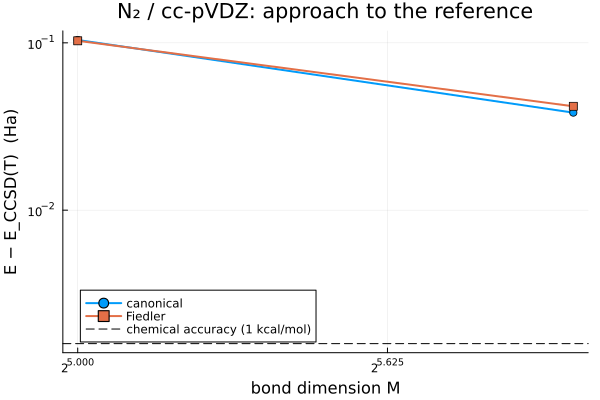

In [19]:
p = plot(; xscale = :log2, yscale = :log10, xlabel = "bond dimension M",
         ylabel = "E − E_CCSD(T)  (Ha)", legend = :bottomleft,
         title = "N₂ / cc-pVDZ: approach to the reference")
floored(rows) = [max(r.E - n2.e_ref, 1e-12) for r in rows]
plot!(p, [r.M for r in can_rows], floored(can_rows); marker = :circle, lw = 2, label = "canonical")
plot!(p, [r.M for r in fied_rows], floored(fied_rows); marker = :square, lw = 2, label = "Fiedler")
hline!(p, [1 / KCAL]; ls = :dash, lc = :black, label = "chemical accuracy (1 kcal/mol)")

## The SU(2) spin-adapted layer

The SU(2) layer conserves the **total spin** instead of the two electron counts separately: states
are built from irreducible multiplets, so a singlet is a singlet by construction.

- The space is `Su2Space(d, N, 2S)` — electrons and total spin — and the energy must agree with the
  abelian one for the same physical state.
- A multiplet is stored once instead of `2S+1` times, so the same accuracy needs a **smaller bond
  dimension**. That is the payoff.

The API is otherwise identical, including the schedule.

In [20]:
lih_su2 = QNTT.Su2Space(lih.d, lih.nelec, abs(lih.ms2))     # N electrons, total spin 2S = 0
H_su2 = QNTT.Hamiltonian(lih_su2, lih.t, lih.v)
@printf("%s   vs abelian %s\n", string(lih_su2), string(space_li))

# The SU(2) analogue of a determinant is a configuration state function. Its per-site codes are
# genealogical COUPLING BRANCHES, not electron spins: :up raises the total spin, :dn lowers it, and
# both add exactly one electron.
csf = QNTT.tt_csf([:occ, :occ, :empty, :empty, :empty, :empty])
@printf("CSF norm %.10f, E = %.10f\n", norm(csf), QNTT.rayleigh_quotient(H_su2, csf) + lih.e_nuc)

Su2Space(d=6, N=4, 2S=0)   vs abelian QnSpace(d=6, Nup=2, Ndn=2)
CSF norm 1.0000000000, E = -7.8620238601


A CSF is a fixed point of the spin-adapted sweep for exactly the reason a determinant is one on the
abelian layer — so the same noise schedule is the remedy.

In [21]:
λ_quiet, _, _ = QNTT.mals(H_su2, csf; bond_dims = [0], eps = 1e-12, max_iter = 40)
# The SU(2) driver takes either flavour (perturbative/White noise is the crate-wide default); this
# cell pins noise_type = :random, the path the printed energy below was recorded against.
λ_su2, x_su2, hist_su2 = QNTT.mals(H_su2, csf; bond_dims = [0],
                                   noise = [1e-4, 1e-4, 1e-4, 1e-5, 1e-5, 0.0, 0.0],
                                   noise_type = :random, eps = 1e-12, max_iter = 40, seed = 3)

@printf("SU(2) from a CSF, noise-free : %.10f\n", λ_quiet + lih.e_nuc)
@printf("SU(2) from a CSF, with noise : %.10f\n", λ_su2 + lih.e_nuc)
@printf("exact FCI (pyscf)            : %.10f\n", lih.e_ref)
@printf("abelian answer               : %.10f\n", E_total)

SU(2) from a CSF, noise-free : -7.8781322022
SU(2) from a CSF, with noise : -7.8824019323


exact FCI (pyscf)            : -7.8824019323
abelian answer               : -7.8824019323


In [22]:
@printf("%-10s %18s %14s %14s\n", "layer", "energy", "max bond dim", "max sector rank")
@printf("%-10s %18.10f %14d %14d\n", "abelian", E_total,
        QNTT.max_bond_rank(x_li), QNTT.max_sector_rank(x_li))
@printf("%-10s %18.10f %14d %14d\n", "SU(2)", λ_su2 + lih.e_nuc,
        QNTT.max_bond_rank(x_su2), QNTT.max_sector_rank(x_su2))
@printf("\nenergies agree to %.1e Ha\n", abs((λ_su2 + lih.e_nuc) - E_total))

layer                  energy   max bond dim max sector rank
abelian         -7.8824019323             23              6


SU(2)           -7.8824019323             10              3

energies agree to 1.8e-15 Ha


Same energy on a smaller manifold; that ratio grows with the spin multiplicity involved. Everything
else transfers unchanged — `Su2Space(data)` reads an FCIDUMP header, and the TDVP, Riemannian
and `rpa` drivers all have SU(2) arms with the same keyword surface.

## The production pipeline, with every knob in view

A real ground state — the kind notebook 03 does linear response *on* — is a **pipeline**:

1. **MALS stage A**, a fixed-`M` ramp *with noise* — noise escapes the determinant/CSF trap, and is
   only safe under a fixed pooled cap (uncapped ranks plus noise is the rank-explosion pathology).
2. **MALS stage B**, noise-free and rank-*adaptive*: a fixed grid cannot move rank between sectors.
3. **A Riemannian CG polish** to genuine criticality. Sweeps converge the *energy*; linear response
   needs `‖grad‖` small, which is stricter and costs the most.
4. **A boundary trim**, then re-polish: near-zero Schmidt directions cost ~`σ²` in energy but put
   ~`1/σ_min` into the Weingarten curvature and stall every downstream solver.

The parameters below are the whole pipeline, ordinary variables. Change one, delete
`notebooks/cache/`, and re-run — the cache is gitignored, rebuilt on demand, and each cached cell
prints whether it hit or missed.

In [23]:
# ---- physical setup ---------------------------------------------------------------------------
# Switch FIXTURE to "lih_sto3g" for a seconds-long smoke run of this entire section. "h2o_631g"
# (13 orbitals, 10 electrons) is the DEMONSTRATED case: notebook 03's real-system section runs its
# stability gate and linear response on exactly this state, and it is why the cache exists at all.
const FIXTURE = "h2o_631g"
const TWO_S   = 0            # total spin 2S — 0 is a singlet. This is 2S, NOT the FCIDUMP's MS2.
const M       = 64           # pooled bond dimension (the conventional DMRG M, summed over sectors)

# ---- MALS stage A: fixed-M ramp WITH noise ------------------------------------------------------
const MALS_A_BOND_DIMS  = [max(M ÷ 4, 6), max(M ÷ 2, 10), max(3M ÷ 4, 14), M, M, M]
const MALS_A_NOISE      = [3e-3, 1e-3, 3e-4, 1e-4, 3e-5, 1e-5, 3e-6, 1e-6,
                           0.0, 0.0, 0.0, 0.0, 0.0, 0.0]      # MUST end at 0.0
const MALS_A_NOISE_TYPE = :random
const MALS_A_EPS        = 1e-10
const MALS_A_MAX_ITER   = 30
const MALS_SEED         = 0x9E3779B9

# ---- MALS stage B: noise-free, rank-adaptive ----------------------------------------------------
# NOTE on the smoke fixture: on a system small enough that stage A already reaches FCI, this
# truncation tolerance becomes the BINDING constraint and stage B raises the energy again. That is
# the stage doing its job (it trades energy for a better-conditioned rank distribution), not a bug —
# but it is why the smoke run's numbers look worse than stage A's.
const MALS_B_EPS      = 1e-2       # truncation tolerance; the stage's real knob
const MALS_B_BOND_CAP = 4M         # a cap, not a target: uncapped drove water to rank 209
const MALS_B_MAX_ITER = 30

# ---- Riemannian CG polish -----------------------------------------------------------------------
const GRADTOL     = 1e-10   # THE criticality gate — the RPA reference criterion
const CG_MAX_ITER = 600     # inner CG iterations before the driver restarts
const CG_GRADTOL  = 1e-13   # the driver's own inner stop, deliberately below GRADTOL
const CG_RESTARTS = 30      # outer restarts allowed while chasing GRADTOL

# ---- boundary trim ------------------------------------------------------------------------------
const TRIM_EPS    = 1e-6
const TRIM_PASSES = 1       # was 3; passes 2-3 measurably buy nothing (the re-polish re-equilibrates)

@printf("fixture %s, 2S = %d, M = %d\n", FIXTURE, TWO_S, M)

fixture h2o_631g, 2S = 0, M = 64


In [24]:
fx = load_fixture(fixture(FIXTURE))
space_gs = QNTT.Su2Space(fx.d, fx.nelec, TWO_S)      # the spin-adapted layer, as notebook 03 needs
t0 = time()
H_gs = QNTT.Hamiltonian(space_gs, fx.t, fx.v)
@printf("%s\n", string(space_gs))
@printf("operator built in %.1f s\n", time() - t0)
@printf("E_nuc = %.9f   E_HF = %.9f   E_ref = %.9f\n", fx.e_nuc, fx.e_hf, fx.e_ref)

# The closed-shell CSF: the spin-adapted analogue of the Hartree-Fock determinant, and — exactly
# like it — a FIXED POINT of the noise-free sweep. That is what stage A's noise is for.
csf0 = QNTT.tt_csf([k <= fx.nelec ÷ 2 ? :occ : :empty for k in 1:fx.d])
@printf("CSF start: E = %.9f Ha\n", QNTT.rayleigh_quotient(H_gs, csf0) + fx.e_nuc)

Su2Space(d=13, N=10, 2S=0)
operator built in 0.5 s


E_nuc = 8.801465569   E_HF = -75.980157922   E_ref = -76.121285071
CSF start: E = -75.980157922 Ha


The pipeline itself. `polish` re-enters `riemannian` until `grad_norm` is below `GRADTOL`: a single
call stops on its own inner criterion, which is not the gate that matters.

In [25]:
"Riemannian CG to criticality: restart until ‖grad‖ < GRADTOL, or give up loudly."
function polish(H, x, λ_scale)
    inner_eps = GRADTOL / max(abs(λ_scale), 1)      # the inner test is RELATIVE to the energy
    _, y = QNTT.riemannian(H, x; cg = true, eps = inner_eps,
                           max_iter = CG_MAX_ITER, gradtol = CG_GRADTOL)
    ncg = 1
    for _ in 1:CG_RESTARTS
        QNTT.grad_norm(H, y) < GRADTOL && break
        _, y = QNTT.riemannian(H, y; cg = true, eps = inner_eps,
                               max_iter = CG_MAX_ITER, gradtol = CG_GRADTOL)
        ncg += 1
    end
    return (y / norm(y), ncg)
end

function ground_state_pipeline(H, x0, e_nuc)
    t_a = @elapsed λa, xa, _ = QNTT.mals(H, x0; bond_dims = MALS_A_BOND_DIMS,
                                         noise = MALS_A_NOISE, noise_type = MALS_A_NOISE_TYPE,
                                         eps = MALS_A_EPS, max_iter = MALS_A_MAX_ITER,
                                         seed = MALS_SEED)
    @printf("  MALS A (M = %d, noisy)      E = %.9f Ha   %5.1f s\n", M, λa + e_nuc, t_a)

    t_b = @elapsed λb, xb, _ = QNTT.mals(H, xa; bond_dims = [MALS_B_BOND_CAP], noise = [0.0],
                                         eps = MALS_B_EPS, max_iter = MALS_B_MAX_ITER)
    @printf("  MALS B (adaptive, eps=%.0e) E = %.9f Ha   %5.1f s\n", MALS_B_EPS, λb + e_nuc, t_b)

    t_p = @elapsed x, ncg = polish(H, xb, λb)
    @printf("  CG polish (%2d calls)       E = %.9f Ha   %5.1f s   ‖grad‖ = %.3e\n",
            ncg, QNTT.rayleigh_quotient(H, x) + e_nuc, t_p, QNTT.grad_norm(H, x))

    for pass in 1:TRIM_PASSES
        t_t = @elapsed begin
            QNTT.round!(x; eps = TRIM_EPS, mode = :rel)
            x = x / norm(x)
            x, nc = polish(H, x, QNTT.rayleigh_quotient(H, x))
        end
        @printf("  trim pass %d (eps=%.0e)      E = %.9f Ha   %5.1f s   σ_min = %.3e\n",
                pass, TRIM_EPS, QNTT.rayleigh_quotient(H, x) + e_nuc, t_t, QNTT.sigma_min(x))
    end
    return x
end

const GS_TAG = @sprintf("%s_2S%d_M%d_gs", FIXTURE, TWO_S, M)
x_gs, how, t_gs = cached(Float64, QNTT.SU2, GS_TAG, space_gs,
                         () -> ground_state_pipeline(H_gs, csf0, fx.e_nuc))
report_cache(GS_TAG, how, t_gs)

cache HIT  h2o_631g_2S0_M64_gs — loaded in 0.000 s (the pipeline below was skipped)


### What "converged" means here

Five numbers, and the last three are the ones a linear-response calculation actually depends on.
An energy that has stopped moving says nothing about any of them.

In [26]:
λ_gs = QNTT.rayleigh_quotient(H_gs, x_gs)
E_gs = λ_gs + fx.e_nuc
sp_gs = QNTT.schmidt(x_gs)

@printf("E                    = %.9f Ha\n", E_gs)
@printf("  vs fixture E_ref   = %.9f Ha   (Δ = %+.2e)\n", fx.e_ref, E_gs - fx.e_ref)
@printf("%% correlation energy = %.2f %%\n", 100 * (fx.e_hf - E_gs) / (fx.e_hf - fx.e_ref))
@printf("pooled bond dims     = %s\n", string([sum(g) for g in QNTT.ranks(x_gs)]))
@printf("max bond / sector    = %d / %d\n", QNTT.max_bond_rank(x_gs), QNTT.max_sector_rank(x_gs))
@printf("σ_min                = %.3e   (the manifold-boundary alarm)\n", QNTT.sigma_min(x_gs))
@printf("‖grad‖               = %.3e   (gate %.0e — %s)\n", QNTT.grad_norm(H_gs, x_gs), GRADTOL,
        QNTT.grad_norm(H_gs, x_gs) < GRADTOL ? "CRITICAL" : "NOT critical")
@printf("ρ = |(x,x)|/⟨x,x⟩    = %.15f   (a real state is 1 by construction)\n", QNTT.rho(x_gs))

# The Schmidt mass, bond by bond. Use the WEIGHTED sum: on the SU(2) layer each reduced multiplet
# carries a degeneracy weight, and the unweighted Σσ² reads ~0.99 and looks like a bug.
println("\nper-bond Schmidt spectrum:")
for (b, (σ, w)) in enumerate(zip(sp_gs.sigma, sp_gs.weight))
    @printf("  bond %2d: %3d values, σ ∈ [%.3e, %.3e], Σ w σ² = %.12f\n",
            b, length(σ), minimum(σ), maximum(σ), sum(w .* σ .^ 2))
end

E                    = -76.119211536 Ha
  vs fixture E_ref   = -76.121285071 Ha   (Δ = +2.07e-03)
% correlation energy = 98.53 %
pooled bond dims     = [1, 2, 4, 11, 29, 66, 88, 79, 66, 46, 18, 7, 3, 1]


max bond / sector    = 88 / 26
σ_min                = 6.217e-04   (the manifold-boundary alarm)
‖grad‖               = 9.219e-11   (gate 1e-10 — CRITICAL)
ρ = |(x,x)|/⟨x,x⟩    = 1.000000000000000   (a real state is 1 by construction)



per-bond Schmidt spectrum:
  bond  1:   2 values, σ ∈ [2.684e-03, 1.000e+00], Σ w σ² = 1.000000000000
  bond  2:   4 values, σ ∈ [2.445e-03, 9.936e-01], Σ w σ² = 1.000000000000


  bond  3:  11 values, σ ∈ [2.178e-03, 9.826e-01], Σ w σ² = 1.000000000000
  bond  4:  29 values, σ ∈ [1.644e-03, 9.777e-01], Σ w σ² = 1.000000000000
  bond  5:  66 values, σ ∈ [8.594e-04, 9.759e-01], Σ w σ² = 1.000000000000
  bond  6:  88 values, σ ∈ [6.456e-04, 9.773e-01], Σ w σ² = 1.000000000000
  bond  7:  79 values, σ ∈ [6.217e-04, 9.805e-01], Σ w σ² = 1.000000000000
  bond  8:  66 values, σ ∈ [9.164e-04, 9.822e-01], Σ w σ² = 1.000000000000
  bond  9:  46 values, σ ∈ [8.421e-04, 9.857e-01], Σ w σ² = 1.000000000000
  bond 10:  18 values, σ ∈ [8.652e-04, 9.898e-01], Σ w σ² = 1.000000000000
  bond 11:   7 values, σ ∈ [7.495e-03, 9.937e-01], Σ w σ² = 1.000000000000
  bond 12:   3 values, σ ∈ [1.929e-02, 9.978e-01], Σ w σ² = 1.000000000000


`σ_min` is a **conditioning** number, not an accuracy measure: the Weingarten curvature scales like
`‖r⊥‖/σ_min`, so a state on the manifold boundary has a Hessian that is undefined, not merely
ill-conditioned. When it collapses the answer is a *smaller* manifold, not a tighter tolerance.

The state is now cached; notebook 03 picks it up from here.

## Optional: point-group and SU(2) symmetry

Two symmetries are switchable, and they switch differently.

**SU(2)** is the *space constructor*: `Su2Space` gives the spin-adapted layer, `QnSpace` the
`Nup`/`Ndn` one. Everything downstream — `mals`, `riemannian`, `rpa`, `pd_probe`, `save` — is
generic over the layer, so it is a one-line change. Note SU(2) ranks are **reduced multiplet**
ranks, so a given `M` is not the same object on the two layers, and the SU(2) singlet layer gives
the singlet spectrum directly where the abelian layer also returns triplets.

**Point group** is a keyword, and the *kind* is chosen once at read time — choosing it later would
silently reinterpret the `ISYM` target. It needs a fixture carrying `ORBSYM`, so it goes through
`read_fcidump`, not the bare `h1`/`h2` pair used above. `screen_forbidden!` is mandatory: a
symmetry-adapted dump carries a ~1e-14 forbidden residue that survives `eps = eps(Float64)` and
trips a hard assert during construction.

It is a **trade, not a free win**: point-group symmetry makes the Hamiltonian more expensive to
build and store in exchange for faster solves. Turn it on where the solver dominates, not by
reflex.

In [27]:
# Symmetry-adapted fixtures in testdata/ (all self-describing FCIDUMPs):
#   h2o_c2v/H2O.FCIDUMP        NORB=7,  NELEC=10, MS2=0   C2v
#   ch2_triplet_c2v/*.FCIDUMP  NORB=7,  NELEC=8,  MS2=2   C2v
#   n2_d2h/*.FCIDUMP           NORB=28, NELEC=14, MS2=0   D2h   <- where the trade actually pays
PG_FIXTURE = fixture("h2o_c2v", "H2O.FCIDUMP")

data_pg = QNTT.read_fcidump(PG_FIXTURE; point_group = :auto)   # :auto, or pin :C1 … :D2h
pg = QNTT.pointgroup(data_pg)
@printf("%s: norb=%d nelec=%d ms2=%d — %s, target %s\n", basename(PG_FIXTURE),
        QNTT.norb(data_pg), QNTT.nelec(data_pg), QNTT.ms2(data_pg), pg.kind, pg.target)

QNTT.screen_forbidden!(data_pg)        # MANDATORY before constructing over a PG space

# All four combinations construct; pick one and the rest of the notebook is unchanged.
for (label, sp) in (("SU(2) + PG ", QNTT.Su2Space(data_pg; two_s = 0, point_group = :inherit)),
                    ("SU(2)      ", QNTT.Su2Space(data_pg; two_s = 0, point_group = nothing)),
                    ("abelian + PG", QNTT.QnSpace(data_pg)))
    H_pg = QNTT.Hamiltonian(sp, data_pg)          # the Hamiltonian is built over the chosen space
    @printf("  %-12s %s\n", label, sp)
end

H2O.FCIDUMP: norb=7 nelec=10 ms2=0 — C2v, target 0
  SU(2) + PG   Su2Space(d=7, N=10, 2S=0, C2v, target=A1)


  SU(2)        Su2Space(d=7, N=10, 2S=0)
  abelian + PG QnSpace(d=7, Nup=5, Ndn=5, C2v, target=A1)
